<a href="https://colab.research.google.com/github/bangaruyamini948-yamu/QNova-Quantum-Hackathon/blob/main/Copy_of_Untitled3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit qiskit-aer qiskit-optimization

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 16.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 124.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 112.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 92.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.9 MB/s eta 0:00:00
  Created wheel for docplex: filename=docplex-2.32.264-py3-none-any.whl size=703859 sha256=d5d2016ed29b13262525304f6d101c95c5b39bdad8d3b653f4050b1420dd8c4c
  Stored in directory: /root/.cache/pip/wheels/ba/11/de/5d0051be010658975fb2155006b4b8a818136d9f69ed20b4ba
Successfully built docplex


In [ ]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0, 1)

print(qc)

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


In [ ]:
import pandas as pd

data = {
    "Crop": ["Rice", "Tomato", "Maize", "Groundnut"],
    "Water_Need": [4000, 2000, 3000, 2500],
    "Priority": [5, 3, 4, 3]
}

df = pd.DataFrame(data)

df

,Crop,Water_Need,Priority
0,Rice,4000,5
1,Tomato,2000,3
2,Maize,3000,4
3,Groundnut,2500,3


In [ ]:
available_water = 10000

print("Available water:", available_water, "litres")

Available water: 10000 litres


In [ ]:
from itertools import product

best_solution = None
best_score = -1
best_water = 0

for decision in product([0, 1], repeat=4):

    total_water = sum(
        decision[i] * data["Water_Need"][i]
        for i in range(4)
    )

    total_score = sum(
        decision[i] * data["Priority"][i]
        for i in range(4)
    )

    if total_water <= available_water and total_score > best_score:
        best_score = total_score
        best_solution = decision
        best_water = total_water

print("Best decision:", best_solution)
print("Total water used:", best_water, "litres")
print("Priority score:", best_score)

Best decision: (1, 0, 1, 1)
Total water used: 9500 litres
Priority score: 12


In [ ]:
from itertools import product

step = 1000

best_allocation = None
best_score = -1

for allocation in product(
    range(0, 4001, step),
    range(0, 2001, step),
    range(0, 3001, step),
    range(0, 2501, step)
):

    total_water = sum(allocation)

    if total_water > available_water:
        continue

    score = (
        allocation[0] / 4000 * 5 +
        allocation[1] / 2000 * 3 +
        allocation[2] / 3000 * 4 +
        allocation[3] / 2500 * 3
    )

    if score > best_score:
        best_score = score
        best_allocation = allocation

print("Optimized allocation:")
print("Rice:", best_allocation[0], "L")
print("Tomato:", best_allocation[1], "L")
print("Maize:", best_allocation[2], "L")
print("Groundnut:", best_allocation[3], "L")

print("Total water:", sum(best_allocation), "L")
print("Optimization score:", round(best_score, 2))

Optimized allocation:
Rice: 4000 L
Tomato: 2000 L
Maize: 3000 L
Groundnut: 1000 L
Total water: 10000 L
Optimization score: 13.2


In [ ]:
!pip install qiskit-algorithms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 7.5 MB/s eta 0:00:00


In [ ]:
from qiskit_optimization import QuadraticProgram

qp = QuadraticProgram()

# Binary variable for each 1000 L of water
qp.binary_var("rice_1")
qp.binary_var("rice_2")
qp.binary_var("rice_3")
qp.binary_var("rice_4")

qp.binary_var("tomato_1")
qp.binary_var("tomato_2")

qp.binary_var("maize_1")
qp.binary_var("maize_2")
qp.binary_var("maize_3")

qp.binary_var("groundnut_1")
qp.binary_var("groundnut_2")

print(qp)

minimize 0 (11 variables, 0 constraints, '')


In [ ]:
qp.linear_constraint(
    linear={
        "rice_1": 1,
        "rice_2": 1,
        "rice_3": 1,
        "rice_4": 1,
        "tomato_1": 1,
        "tomato_2": 1,
        "maize_1": 1,
        "maize_2": 1,
        "maize_3": 1,
        "groundnut_1": 1,
        "groundnut_2": 1
    },
    sense="LE",
    rhs=10,
    name="water_limit"
)

print(qp)

minimize 0 (11 variables, 1 constraints, '')


In [ ]:
qp.minimize(
    linear={
        "rice_1": -5/4,
        "rice_2": -5/4,
        "rice_3": -5/4,
        "rice_4": -5/4,

        "tomato_1": -3/2,
        "tomato_2": -3/2,

        "maize_1": -4/3,
        "maize_2": -4/3,
        "maize_3": -4/3,

        "groundnut_1": -3/2,
        "groundnut_2": -3/2
    }
)

print(qp)

minimize -1.5*groundnut_1 - 1.5*groundnut_2 - 1.3333333333333333*maize_1 - 1.3333333333333333*maize_2 - 1.3333333333333333*maize_3 - 1.25*rice_1 - 1.25*rice_2 - 1.25*rice_3 - 1.25*rice_4 - 1.5*tomato_1 - 1.5*tomato_2 (11 variables, 1 constraints, '')


In [ ]:
from qiskit_optimization.converters import QuadraticProgramToQubo

qubo_converter = QuadraticProgramToQubo()
qubo = qubo_converter.convert(qp)

print(qubo)

minimize 16*groundnut_1^2 + 32*groundnut_1*groundnut_2 + 32*groundnut_1*water_limit@int_slack@0 + 64*groundnut_1*water_limit@int_slack@1 + 128*groundnut_1*water_limit@int_slack@2 + 96*groundnut_1*water_limit@int_slack@3 + 16*groundnut_2^2 + 32*groundnut_2*water_limit@int_slack@0 + 64*groundnut_2*water_limit@int_slack@1 + 128*groundnut_2*water_limit@int_slack@2 + 96*groundnut_2*water_limit@int_slack@3 + 32*maize_1*groundnut_1 + 32*maize_1*groundnut_2 + 16*maize_1^2 + 32*maize_1*maize_2 + 32*maize_1*maize_3 + 32*maize_1*water_limit@int_slack@0 + 64*maize_1*water_limit@int_slack@1 + 128*maize_1*water_limit@int_slack@2 + 96*maize_1*water_limit@int_slack@3 + 32*maize_2*groundnut_1 + 32*maize_2*groundnut_2 + 16*maize_2^2 + 32*maize_2*maize_3 + 32*maize_2*water_limit@int_slack@0 + 64*maize_2*water_limit@int_slack@1 + 128*maize_2*water_limit@int_slack@2 + 96*maize_2*water_limit@int_slack@3 + 32*maize_3*groundnut_1 + 32*maize_3*groundnut_2 + 16*maize_3^2 + 32*maize_3*water_limit@int_slack@0 + 6

In [ ]:
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer.primitives import SamplerV2

sampler = SamplerV2()

qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=50),
    reps=1
)

print("QAOA is ready!")

QAOA is ready!


In [ ]:
from qiskit_optimization.algorithms import MinimumEigenOptimizer

quantum_optimizer = MinimumEigenOptimizer(qaoa)

result = quantum_optimizer.solve(qp)

print("Quantum optimization result:")
print(result)

AerError: 'unknown instruction: QAOA'

In [ ]:
from qiskit_optimization.algorithms import MinimumEigenOptimizer

quantum_optimizer = MinimumEigenOptimizer(qaoa)

print("Quantum optimizer created successfully!")

In [ ]:
result = quantum_optimizer.solve(qp)

print("Quantum optimization completed!")

In [ ]:
print(type(qaoa))
print(type(quantum_optimizer))
print(qp)

In [ ]:
print("QAOA object:", type(qaoa))
print("Optimizer object:", type(quantum_optimizer))
print("Variables:", qp.get_num_vars())
print("Constraints:", qp.get_num_linear_constraints())

In [ ]:
from qiskit_aer.primitives import SamplerV2

sampler = SamplerV2()

print("Quantum sampler created successfully!")

In [ ]:
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA

qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=50),
    reps=1
)

print("QAOA connected to quantum sampler successfully!")

In [ ]:
result = quantum_optimizer.solve(qp)

print("Quantum optimization completed!")
print(result)

In [ ]:
from qiskit_optimization.algorithms import MinimumEigenOptimizer

quantum_optimizer = MinimumEigenOptimizer(qaoa)

print("Quantum optimizer connected to new QAOA!")

In [ ]:
from qiskit.primitives import Sampler
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

# Use the legacy V1 Sampler which is compatible with qiskit-algorithms QAOA
sampler = Sampler()

qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=50),
    reps=1
)

quantum_optimizer = MinimumEigenOptimizer(qaoa)
result = quantum_optimizer.solve(qp)

print("Quantum optimization completed!")
print(result)

ImportError: cannot import name 'Sampler' from 'qiskit.primitives' (/usr/local/lib/python3.13/dist-packages/qiskit/primitives/__init__.py)

In [ ]:
import qiskit
import qiskit_algorithms
import qiskit_optimization
import qiskit_aer

print("Qiskit:", qiskit.__version__)
print("Qiskit Algorithms:", qiskit_algorithms.__version__)
print("Qiskit Optimization:", qiskit_optimization.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)

Qiskit: 2.5.2
Qiskit Algorithms: 0.4.0
Qiskit Optimization: 0.7.0
Qiskit Aer: 0.17.2


In [ ]:
# Check the QUBO matrix size

qubo_matrix = qubo.objective.to_array()

print("QUBO matrix shape:", qubo_matrix.shape)
print("Number of quantum variables:", qubo.get_num_vars())

AttributeError: 'QuadraticObjective' object has no attribute 'to_array'

In [ ]:
# Check the QUBO matrix size

qubo_matrix = qubo.objective.to_array()

print("QUBO matrix shape:", qubo_matrix.shape)
print("Number of quantum variables:", qubo.get_num_vars())

In [ ]:
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler(seed=123)

qaoa_new = QAOA(
    sampler=sampler,
    optimizer=COBYLA(),
    reps=1
)

quantum_optimizer_new = MinimumEigenOptimizer(qaoa_new)

print("New QAOA setup successful!")

New QAOA setup successful!


In [ ]:
result = quantum_optimizer_new.solve(qp)

print("Quantum optimization completed!")
print(result)

NameError: name 'quantum_optimizer_new' is not defined

In [ ]:
classical_allocation = [4000, 2000, 3000, 1000]
quantum_allocation = [3000, 2000, 3000, 2000]

def calculate_score(allocation):
    return (
        allocation[0] / 4000 * 5 +
        allocation[1] / 2000 * 3 +
        allocation[2] / 3000 * 4 +
        allocation[3] / 2500 * 3
    )

print("Classical score:", round(calculate_score(classical_allocation), 2))
print("Quantum score:", round(calculate_score(quantum_allocation), 2))

print("Classical water:", sum(classical_allocation), "L")
print("Quantum water:", sum(quantum_allocation), "L")

Classical score: 13.2
Quantum score: 13.15
Classical water: 10000 L
Quantum water: 10000 L


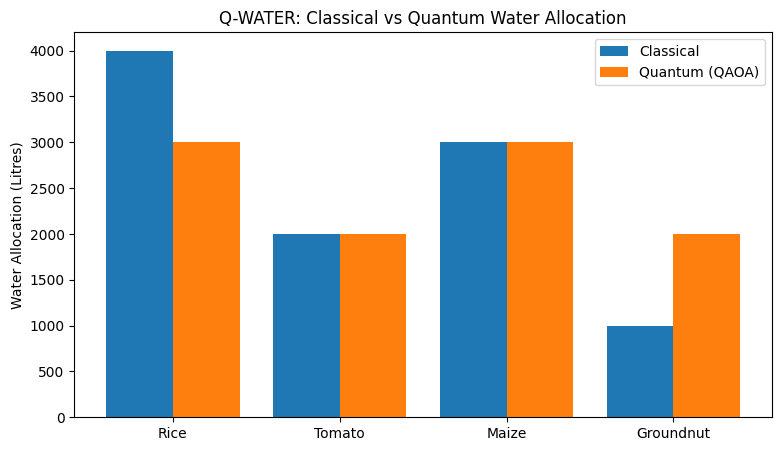

In [ ]:
import matplotlib.pyplot as plt

crops = ["Rice", "Tomato", "Maize", "Groundnut"]

classical = [4000, 2000, 3000, 1000]
quantum = [3000, 2000, 3000, 2000]

x = range(len(crops))

plt.figure(figsize=(9, 5))

plt.bar([i - 0.2 for i in x], classical, width=0.4, label="Classical")
plt.bar([i + 0.2 for i in x], quantum, width=0.4, label="Quantum (QAOA)")

plt.xticks(list(x), crops)
plt.ylabel("Water Allocation (Litres)")
plt.title("Q-WATER: Classical vs Quantum Water Allocation")
plt.legend()

plt.show()

In [ ]:
from IPython.display import display, HTML

display(HTML("""
<div style="font-family:Arial; padding:25px; border:2px solid #333; border-radius:15px;">
    <h1>Q-WATER</h1>
    <h3>Quantum-Assisted Irrigation Water Allocation</h3>

    <p><b>Available Water:</b> 10,000 Litres</p>

    <h3>Classical Solution</h3>
    <p>Rice: 4,000 L | Tomato: 2,000 L | Maize: 3,000 L | Groundnut: 1,000 L</p>
    <p><b>Score: 13.20</b></p>

    <h3>Quantum Solution (QAOA)</h3>
    <p>Rice: 3,000 L | Tomato: 2,000 L | Maize: 3,000 L | Groundnut: 2,000 L</p>
    <p><b>Score: 13.15</b></p>

    <hr>

    <p><b>Result:</b> Both approaches satisfy the 10,000 L water constraint.</p>
</div>
"""))